# Where cells sit in the cycle

A knockout that stalls the cell cycle changes how much DNA its cells hold. The tutorial first places single cells on
the cycle from their DNA stain alone, with {func}`~mantispy.tl.fit_cell_cycle` and
{func}`~mantispy.tl.project_cell_cycle`. It then shows what the other features add, and reads the result for
knockouts whose effect on the cycle is known.

The cells come from an optical pooled CRISPR screen in HeLa cells ({func}`~mantispy.ds.aconcagua`), eight genes and
the non-targeting controls, imaged with a DAPI stain. Each gene's function predicts a place in the cycle, so we state
the predictions before looking:

| Gene | Function | Prediction |
| --- | --- | --- |
| RRM1 | makes the nucleotides DNA replication needs | more cells in S |
| HAUS6, SKA2 | build and attach the mitotic spindle | more cells in G2M |
| DTL | stops DNA from being copied twice in one cycle | more cells above 4N, off the cycle |
| PSMB7 | a proteasome subunit, without which cells pile up before and in mitosis | more cells in G2M |
| SF3B3 | a spliceosome subunit, whose loss stalls cells both in G1 and at G2 and M | more cells in G2M |
| ITGAV, TLN1 | cell adhesion, no cell-cycle role | the same as the controls |

The [optical pooled screens case study](../../case_studies/optical_pooled_screens.ipynb) puts these genes in the
context of the whole screen, and [how the cell-cycle model works](cell_cycle_method.ipynb) explains the model step by
step.

The input is the integrated intensity of a DNA stain, such as DAPI or Hoechst, per nucleus, raw and not normalized,
since a normalized feature no longer doubles from G1 to G2. A pipeline that measured the image background should
subtract it first. The reference cells are those with ``Metadata_Control_Type`` set to ``"negcon"``, and they must
be cycling normally. When the feature name is not given, {func}`~mantispy.tl.dna_content` looks for a ``Nuclei_``
integrated intensity whose channel is DNA, DAPI or Hoechst.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mantispy as mt

plt.rcParams["figure.dpi"] = 110

cells = mt.ds.aconcagua(cells=True)
cells.obs["Metadata_Gene"].value_counts().rename("cells").to_frame().T

Metadata_Gene,nontargeting,TLN1,SF3B3,HAUS6,ITGAV,PSMB7,RRM1,DTL,SKA2
cells,24166,2049,1984,1969,1921,1903,1890,1830,962


## DNA content

{func}`~mantispy.tl.dna_content` turns the integrated DAPI intensity into DNA content in doublings, the log2 of the
intensity over that of the G1 peak. A G1 nucleus sits near 0, and a nucleus with twice that DNA sits near 1. We
call the two amounts 2N and 4N, as is usual for the G1 and G2 DNA content. HeLa cells are hypertriploid, so their
G1 nuclei in fact hold more than two copies of most chromosomes.

Staining differs between wells, so in a pooled screen the G1 peak is found per well. Every well also holds
non-targeting cells, and ``reference="negcon"`` finds the peak on those alone. A knockout that empties G1 then
cannot move the peak of its well. In an arrayed screen, where a well holds one treatment, pass ``by="Metadata_Plate"``
instead, so the controls of each plate set its peak.

In [2]:
mt.tl.dna_content(
    cells,
    dna_feature="Nuclei_Intensity_IntegratedIntensity_DAPI",
    by=("Metadata_Plate", "Metadata_Well"),
    reference="negcon",
)

## Where each cell sits

{func}`~mantispy.tl.fit_cell_cycle` fits the cycle model on the non-targeting cells. It first checks that they cycle:
a 2N peak, a separate 4N peak and S cells between them. It then describes their DNA content as a G1 peak, a G2M peak,
S cells along a straight line in the amount of DNA between the two, and a flat background for cells off the cycle.
It fits the share of cells in each phase, and keeps the measured peaks rather than assuming 0 and 1.

Ergodic rate analysis {cite:p}`Kafri_2013` turns the phase shares into positions in the cycle. In a population growing
in steady state, younger cells outnumber older ones in a known way, so the share of cells in a phase gives the share
of the cycle the phase takes. Position 0 is the start of G1 and 1 is division, and a position is a fraction of the cycle,
not a time in hours. The model assumes the controls grow in steady state. It cannot tell resting G0 cells from G1
cells, since both hold 2N. With ``qc_features``, the fit also learns shape cutoffs from the controls, used further
down.

In [3]:
mt.tl.fit_cell_cycle(cells, reference="negcon", qc_features=("Nuclei_AreaShape_Area", "Nuclei_AreaShape_Solidity"))
model = cells.uns["mantispy"]["cell_cycle"]
edges = -np.log2(1 - np.cumsum(model["fractions"])[:2] / 2)  # the ages of a growing population, in cycles
print("share of the cycle in G1, S and G2M:", np.round(np.diff(np.r_[0, edges, 1]), 2))
pd.Series(
    {
        "passed the check": model["passed"],
        "2N peak (doublings)": round(model["peaks"][0], 3),
        "4N peak (doublings)": round(model["peaks"][1], 3),
        "2N peak width (doublings)": round(model["sd"], 3),
        "share in G1": round(model["fractions"][0], 2),
        "share in S": round(model["fractions"][1], 2),
        "share in G2M": round(model["fractions"][2], 2),
        "share off the cycle": round(model["off_cycle"], 3),
    }
)

share of the cycle in G1, S and G2M: [0.57 0.3  0.14]


passed the check              True
2N peak (doublings)         -0.005
4N peak (doublings)           0.92
2N peak width (doublings)    0.096
share in G1                   0.65
share in S                    0.25
share in G2M                   0.1
share off the cycle          0.023
dtype: object

The controls pass the check. Their 2N peak sits at -0.005 doublings and their 4N peak at 0.92, short of 1, as happens
when the image background is not subtracted (see [how the model works](cell_cycle_method.ipynb)). Of the control
cells on the cycle, 65% are in G1, 25% in S and 10% in G2M, and the fit puts 2.3% of all control cells off the cycle.
Converted with the age distribution, these shares of cells become 57%, 30% and 14% of the cycle.

{func}`~mantispy.tl.project_cell_cycle` places every cell, knockouts included, on the controls' cycle model. For each
cell it computes a posterior, a probability for every position in the cycle given the cell's DNA content. It writes:

- ``obsm["cell_cycle_probabilities"]``: the probability of G1, S, G2M and off-cycle;
- ``obs["cell_cycle_phase"]``: the most probable of the four, a convenience for counting;
- ``obs["cell_cycle_position"]`` and ``obsm["cell_cycle_quantiles"]``: the median of the posterior and its 5%, 25%,
  75% and 95% quantiles, for cells on the cycle;
- ``obs["cell_cycle_qc"]`` and ``uns["mantispy"]["cell_cycle_wells"]``: checks on the nuclei and on each well's
  stain, used further down.

In [4]:
mt.tl.project_cell_cycle(cells)
example = cells.obs.groupby("cell_cycle_phase", observed=True).head(1).index
pd.concat(
    [
        cells.obs.loc[example, ["Metadata_DNAContent", "cell_cycle_phase"]],
        cells.obsm["cell_cycle_probabilities"].loc[example],
        cells.obsm["cell_cycle_quantiles"].loc[example],
    ],
    axis=1,
).round(2)

,Metadata_DNAContent,cell_cycle_phase,G1,S,G2M,off-cycle,5%,25%,50%,75%,95%
0,0.14,G1,0.79,0.20,0.00,0.00,0.03,0.16,0.33,0.53,0.62
1,0.27,S,0.13,0.85,0.00,0.02,0.18,0.61,0.63,0.65,0.68
3,1.00,G2M,0.00,0.18,0.81,0.01,0.83,0.87,0.91,0.96,0.99
5,1.45,off-cycle,0.00,0.00,0.00,1.00,NaN,NaN,NaN,NaN,NaN


In the table, a cell at 0.14 doublings is in G1 with probability 0.79 and in S with 0.20, since a cell early in S
holds little more DNA than one in G1. A cell at 0.27 doublings is in S with probability 0.85, and the middle half of
its posterior spans only 0.61 to 0.65 of the cycle. A cell at 1.45 doublings is off the cycle and has no position.

DNA content is flat at 2N through G1 and at 4N through G2M, and the width of either peak is measurement noise, not
progress. So DNA content places a cell precisely only in S. Within G1 and G2M the posterior is the population prior.
A cell there is more likely early than late, as the controls' age distribution says, but its own DNA does not tell
where. Don't correlate the position with morphology inside those phases, since any order found there comes from the
other measurements, not from the DNA.

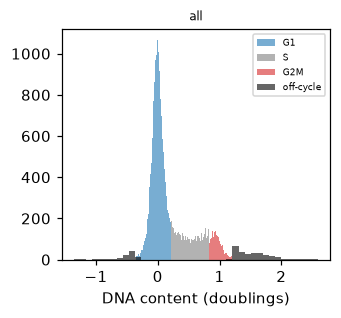

cell_cycle_phase
G1           0.670
S            0.196
G2M          0.120
off-cycle    0.015
Name: proportion, dtype: float64

In [5]:
controls = cells[cells.obs["Metadata_Control_Type"] == "negcon"]
mt.pl.cell_cycle(controls, dna_feature="Metadata_DNAContent", key="cell_cycle_phase", by=None)
plt.gca().set_xlabel("DNA content (doublings)")
plt.show()
controls.obs["cell_cycle_phase"].value_counts(normalize=True).round(3)

The controls' DNA content shows the G1 peak at 0, S cells in the gap and the G2M peak just below 1. Counted by
their most probable phase, 67% of control cells are in G1, 20% in S, 12% in G2M and 1.5% off the cycle, a little
different from the fitted shares, since the most probable phase gives some early S cells to G1 and some late S cells
to G2M. The 1.5% off the cycle is the baseline a knockout's off-cycle share is compared with.

## The cell-cycle clock

{func}`~mantispy.pl.cell_cycle_clock` draws the same placement as a ring, with position 0 at the top. Each cell's
angle is a position drawn from its posterior, so the ring fills. The S arc places each cell from its own DNA, and the
G1 and G2M wedges are shaded and labelled as the population prior.

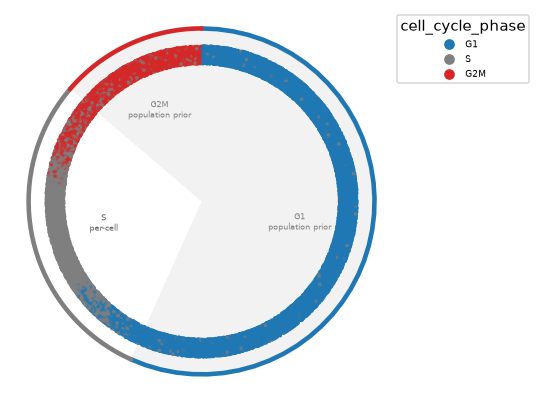

In [6]:
mt.pl.cell_cycle_clock(cells, color="cell_cycle_phase")

## What the other features add

DNA content cannot order cells within G2M, but the other measurements may. With ``refine_g2m=True``,
{func}`~mantispy.tl.fit_cell_cycle` also fits a label-free order there. A regression of DNA content on every feature not
measured on the DNA stain, fitted on the controls' S cells, gives an axis that runs on into G2M.
{func}`~mantispy.tl.project_cell_cycle` then smooths the order along that axis over the G2M cells' nearest neighbors
and writes it to ``obs["cell_cycle_g2m_order"]``, from 0 to 1 within G2M. Positions and phase probabilities stay as
they were.

The option is off by default and experimental, since the order cannot be trusted without a marker of G2 and mitosis
([why it is experimental](cell_cycle_method.ipynb#why-it-is-experimental)). Here the screen's own image classifier, whose interphase and
mitotic labels are in ``Metadata_Class``, serves as that check, and only as a check.

In [7]:
from sklearn.metrics import roc_auc_score

mt.tl.fit_cell_cycle(
    cells, reference="negcon", qc_features=("Nuclei_AreaShape_Area", "Nuclei_AreaShape_Solidity"), refine_g2m=True
)
mt.tl.project_cell_cycle(cells)
model = cells.uns["mantispy"]["cell_cycle"]
check = (cells.obs["cell_cycle_phase"] == "G2M") & (cells.obs["Metadata_Control_Type"] == "negcon")
order = cells.obs.loc[check, "cell_cycle_g2m_order"].to_numpy()
is_mitotic = (cells.obs.loc[check, "Metadata_Class"] == "Mitotic").to_numpy()
print(f"AUROC of the G2M order for mitotic calls, control cells in G2M: {roc_auc_score(is_mitotic, order):.2f}")
quarter = pd.qcut(order, 4, labels=["first", "second", "third", "fourth"])
pd.Series(is_mitotic).groupby(quarter, observed=True).mean().rename("share mitotic").round(3)

project_cell_cycle: the G2M order is experimental and cannot be validated without a marker of G2 and mitosis; check it against one before reading it biologically


AUROC of the G2M order for mitotic calls, control cells in G2M: 0.85


first     0.054
second    0.062
third     0.374
fourth    0.717
Name: share mitotic, dtype: float64

On these controls the order follows mitosis. Mitotic cells sit late in it, with an AUROC of 0.85, and the share
of mitotic cells rises from 5% in the first quarter of the order to 72% in the last. The check covers one dataset that
happens to carry a label. On a screen without one, nothing in the output says whether the order means the same thing,
so read it only next to a marker.

With the order present, the clock places G2M cells along their wedge by it and labels the wedge as the experimental
order. Highlighting the classifier's mitotic calls among the controls shows where they land.

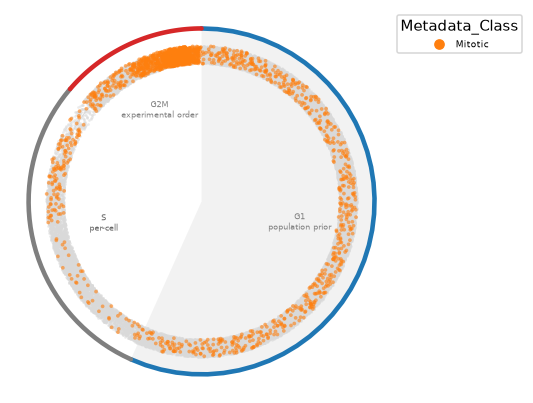

In [8]:
controls = cells[cells.obs["Metadata_Control_Type"] == "negcon"]
mt.pl.cell_cycle_clock(controls, color="Metadata_Class", groups=["Mitotic"])

Mitotic calls pile up at the late end of the G2M wedge, just before division, where the order puts them. Others
spread over the G1 wedge, since about a quarter of all mitotic calls sit at 2N, as a table further down shows. There
the angle follows the prior, so they spread rather than gather. Some fall in S.

## Effects of the knockouts

The DNA content of each gene's cells, colored by phase, shows the effects before any test.

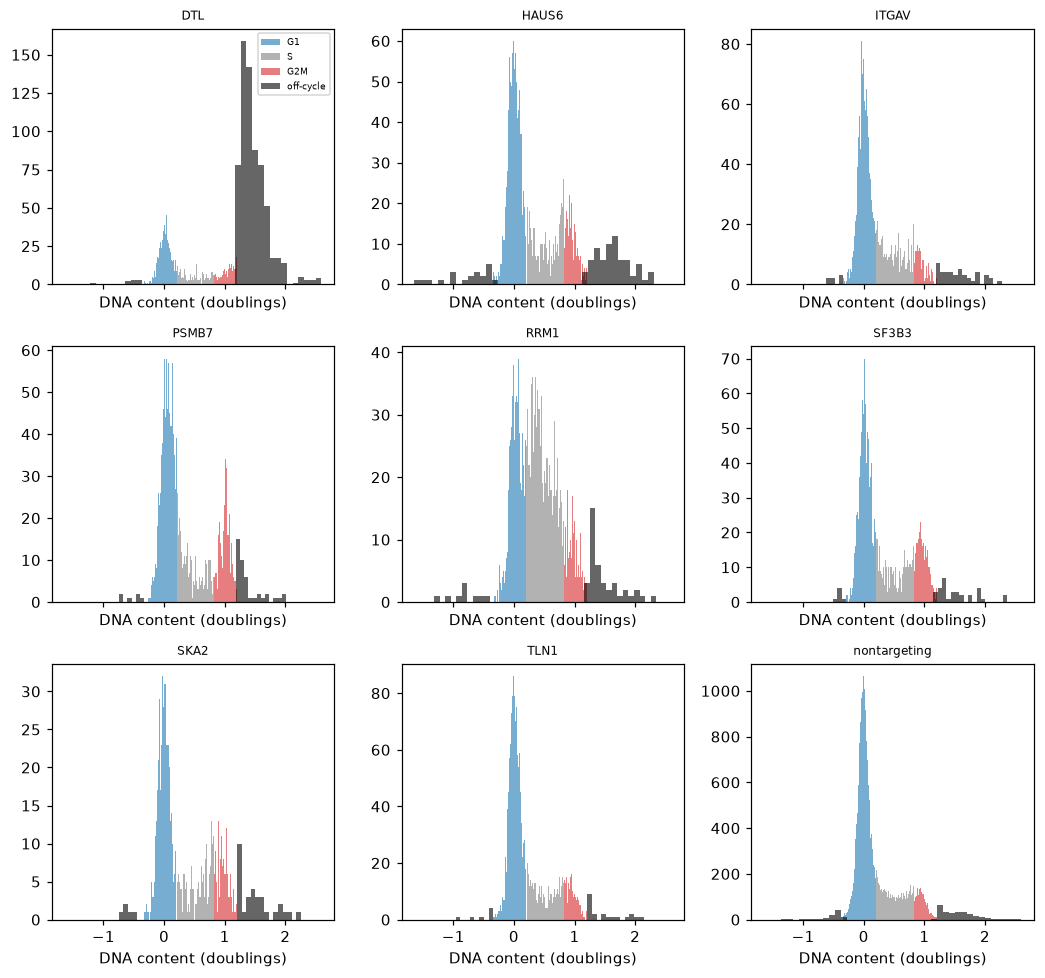

In [9]:
mt.pl.cell_cycle(cells, dna_feature="Metadata_DNAContent", key="cell_cycle_phase", by="Metadata_Gene", ncols=3)
for axis in plt.gcf().axes:
    axis.set_xlabel("DNA content (doublings)")
plt.show()

RRM1 fills S, DTL piles up above 4N, and PSMB7 and SF3B3 raise their 4N peak. HAUS6 adds some cells above 4N as
well as at 4N, while ITGAV and TLN1 look like the controls.

{func}`~mantispy.tl.composition_shift` tests each gene's phase shares against the controls'. It compares shares within
each well and takes the guide as the unit. The p-value comes from relabeling whole guides, since cells of one guide
share the guide's efficiency and are not independent. With 999 permutations, a q-value cannot go much below 0.003,
and four guides per gene limit how small an effect the test can find. The test counts the most probable phase. The
expected change beside it counts each cell by its probabilities instead. For ITGAV and TLN1, where no phase is
predicted, the change column gives the total variation distance over all phases.

In [10]:
mt.tl.composition_shift(
    cells, key="cell_cycle_phase", groupby="Metadata_Gene", replicate="Metadata_Guide", n_permutations=999
)
shift = cells.uns["mantispy"]["composition_shift"].set_index("group")
gene = cells.obs["Metadata_Gene"].astype(str).to_numpy()
soft = cells.obsm["cell_cycle_probabilities"].groupby(gene).mean()
soft_change = soft - soft.loc["nontargeting"]

predicted = {
    "RRM1": "S",
    "HAUS6": "G2M",
    "SKA2": "G2M",
    "DTL": "off-cycle",
    "PSMB7": "G2M",
    "SF3B3": "G2M",
    "ITGAV": None,
    "TLN1": None,
}
rows = []
for name, phase in predicted.items():
    significant = shift.loc[name, "qvalue"] < 0.05
    rows.append(
        {
            "gene": name,
            "predicted phase": phase or "no change",
            "change": shift.loc[name, phase] if phase else shift.loc[name, "distance"],
            "expected change": soft_change.loc[name, phase] if phase else np.nan,
            "qvalue": shift.loc[name, "qvalue"],
            "holds": bool(significant and shift.loc[name, phase] > 0.05) if phase else not significant,
        }
    )
pd.DataFrame(rows).set_index("gene").round(3)

,predicted phase,change,expected change,qvalue,holds
gene,,,,,
RRM1,S,0.278,0.255,0.003,True
HAUS6,G2M,0.096,0.078,0.024,True
SKA2,G2M,0.107,0.090,0.003,True
DTL,off-cycle,0.352,0.346,0.003,True
PSMB7,G2M,0.135,0.108,0.008,True
SF3B3,G2M,0.116,0.092,0.040,True
ITGAV,no change,0.030,NaN,0.407,True
TLN1,no change,0.034,NaN,0.360,True


Every predicted gain is significant, and ITGAV and TLN1 show no significant change. RRM1 gains 28 percentage points
of its cells in S, and DTL gains 35 off the cycle. HAUS6, SKA2, PSMB7 and SF3B3 gain 9.6 to 13.5 points in G2M, with
q-values from 0.003 to 0.04. ITGAV and TLN1 sit at a total variation distance of 0.03 from the controls, with
q-values of 0.41 and 0.36, which shows no change was found, not that there is none. SF3B3's G1 share falls rather
than rises, so of the stall its function predicts, only the G2 and M part shows.

Highlighting three of the knockouts on the clock, against a grey background of all the other cells, shows where each
one lands.

Metadata_Gene
RRM1            0.73
HAUS6           0.57
DTL             0.45
nontargeting    0.45
Name: median order within G2M, dtype: float64

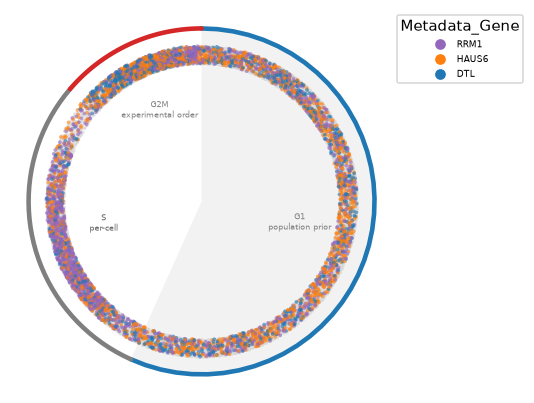

In [11]:
mt.pl.cell_cycle_clock(cells, color="Metadata_Gene", groups=["RRM1", "HAUS6", "DTL"])
in_g2m = cells.obs[cells.obs["cell_cycle_phase"] == "G2M"]
in_g2m.groupby("Metadata_Gene", observed=True)["cell_cycle_g2m_order"].median().loc[
    ["RRM1", "HAUS6", "DTL", "nontargeting"]
].rename("median order within G2M").round(2)

RRM1's cells, in purple, crowd the S arc. Within G2M, HAUS6's cells sit later in the experimental order than the
controls', at a median of 0.57 against 0.45, as expected for cells held in mitosis. RRM1's G2M cells sit later still,
at 0.73. Nothing here explains that, which is a reminder that the order needs a marker before it is read. DTL's
cells, in blue, spread around the ring at the controls' median order in G2M. Its main effect, an arrest above 4N, is
off the cycle, and those cells have no position.

The guides of a gene should agree. The table gives each guide's share of cells per phase.

In [12]:
per_guide = pd.crosstab(
    [cells.obs["Metadata_Gene"], cells.obs["Metadata_Guide"]], cells.obs["cell_cycle_phase"], normalize="index"
)
per_guide.drop(index="nontargeting", level=0).round(2)

cell_cycle_phase                G1     S   G2M  off-cycle
Metadata_Gene Metadata_Guide                             
DTL           ACAGCTGTATT     0.27  0.09  0.22       0.42
              AGGTGATAAAC     0.47  0.14  0.17       0.22
              TGAAGCTGCCT     0.31  0.11  0.16       0.42
              TTTCCAGCAAA     0.30  0.14  0.14       0.42
HAUS6         AAATTATATGA     0.33  0.22  0.36       0.09
              AACTTGAGATC     0.62  0.20  0.15       0.03
              ATGCATTTGTG     0.58  0.20  0.18       0.04
              CTGATTCCTTA     0.51  0.22  0.22       0.04
ITGAV         AACGATGAGCT     0.69  0.20  0.10       0.01
              AAGTTACTTCG     0.65  0.21  0.11       0.03
              AGAACATGACT     0.63  0.21  0.12       0.04
              GCACCTCTCTT     0.62  0.24  0.12       0.02
PSMB7         AACTGGCACGA     0.40  0.23  0.33       0.04
              GAAAACGTTAC     0.48  0.21  0.28       0.03
              GCAGATACAAG     0.62  0.15  0.21       0.02
              TAAGTTGCCTT     0.54  0.19  0.25       0.02
RRM1          CCTACCTAGAA     0.29  0.48  0.20       0.02
              CTTGTACCCCA     0.32  0.52  0.13       0.03
              GTAATCCAAGG     0.31  0.55  0.11       0.02
              TGGCAAACACT     0.43  0.38  0.16       0.03
SF3B3         AAGAATAGCTC     0.43  0.18  0.38       0.02
              AGCAGACAATG     0.66  0.17  0.16       0.02
              CCACAGGCCAC     0.44  0.23  0.31       0.02
              TGAGCCGGATC     0.52  0.18  0.28       0.01
SKA2          CAACAGCAACT     0.47  0.26  0.23       0.04
              GGATTACATTC     0.52  0.21  0.25       0.02
              GGTCGATAAGC     0.50  0.17  0.32       0.01
              TCATCCTGATT     0.58  0.17  0.20       0.04
TLN1          AACTGTGAAGA     0.60  0.23  0.16       0.02
              CAAGCTTAAAC     0.66  0.18  0.15       0.01
              GCGGCAGGCGT     0.70  0.19  0.10       0.02
              GGAAGAACAAG     0.64  0.18  0.17       0.01

The guides mostly agree, but several genes have one guide that differs. One HAUS6 guide, AAATTATATGA, has 36% of
its cells in G2M against 15% to 22% for the other three, and one SF3B3 guide, AGCAGACAATG, looks close to the
controls. One DTL guide has 22% of its cells off the cycle against 42% for the others, and one RRM1 guide 38% in S
against about half.

### Mitosis or G2

Splitting each gene's G2M calls by ``Metadata_Class`` shows which knockouts stop cells in mitosis and which before it.
The split only covers cells called G2M. A quarter of the cells the classifier calls mitotic are called G1 (second
table), so the gains in M likely underestimate the change.

In [13]:
called = cells.obs["cell_cycle_phase"].astype(str)
mitotic = cells.obs["Metadata_Class"] == "Mitotic"
split = called.where(called != "G2M", np.where(mitotic, "M", "G2"))
by_gene = pd.crosstab(cells.obs["Metadata_Gene"], split, normalize="index")[["G1", "S", "G2", "M", "off-cycle"]]
(by_gene - by_gene.loc["nontargeting"]).round(3)

cell_cycle_phase,G1,S,G2,M,off-cycle
Metadata_Gene,,,,,
DTL,-0.330,-0.082,0.087,-0.026,0.351
HAUS6,-0.137,0.011,-0.006,0.101,0.031
ITGAV,-0.027,0.020,0.006,-0.010,0.011
PSMB7,-0.138,-0.009,0.155,-0.019,0.011
RRM1,-0.321,0.278,0.055,-0.023,0.011
SF3B3,-0.112,-0.010,0.088,0.029,0.005
SKA2,-0.133,0.005,0.015,0.090,0.023
TLN1,-0.033,0.007,0.015,0.013,-0.001
nontargeting,0.000,0.000,0.000,0.000,0.000


In [14]:
pd.crosstab(cells.obs["cell_cycle_phase"], cells.obs["Metadata_Class"], normalize="columns").round(3)

Metadata_Class,Interphase,Mitotic
cell_cycle_phase,,
G1,0.645,0.248
S,0.213,0.137
G2M,0.113,0.505
off-cycle,0.029,0.109


HAUS6 and SKA2 gain 10 and 9 percentage points of their cells in mitosis and almost none in G2, consistent with
an arrest in mitosis, as spindle defects predict. PSMB7 gains 16 points in G2 and has slightly fewer cells in mitosis than
the controls, and DTL gains 9 points in G2, consistent with an arrest before mitosis. For PSMB7 that matches only the G2 half of the prediction.
SF3B3 gains 9 points in G2 and 3 in mitosis. Half of the cells the classifier calls mitotic (51%) are in G2M, and a
quarter (25%) sit at 2N, possibly anaphase figures segmented as two nuclei, or classifier errors.

### DTL's nuclei above 4N

Merged nuclei and fragments can sit above 4N or below 2N for reasons unrelated to the cycle. Cells that died before
imaging are missing altogether, so a knockout that kills its arrested cells shows fewer of them than it made. ``cell_cycle_qc`` gives the
first shape check a nucleus fails, with cutoffs learned from the controls:

- ``"irregular"``: a solidity, the nucleus' area over that of its convex hull, below the controls', as merged nuclei
  and mitotic figures have;
- ``"small"``: an area below the controls', as fragments have;
- ``"dim"``: too little DNA per area;
- ``"ok"``: none of these.

The table takes as above 4N a DNA content more than 0.35 doublings past the 4N peak.

In [15]:
shape = cells[:, ["Nuclei_AreaShape_Area", "Nuclei_AreaShape_Solidity"]].to_df()
above = cells.obs["Metadata_DNAContent"] > model["peaks"][1] + 0.35
pd.DataFrame(
    {
        "nuclei above 4N": above.groupby(gene).sum(),
        "median area": shape.loc[above, "Nuclei_AreaShape_Area"].groupby(gene[above]).median(),
        "median solidity": shape.loc[above, "Nuclei_AreaShape_Solidity"].groupby(gene[above]).median(),
        "share irregular": (cells.obs.loc[above, "cell_cycle_qc"] == "irregular").groupby(gene[above]).mean(),
        "share mitotic": mitotic[above].groupby(gene[above]).mean(),
    }
).round(3)

,nuclei above 4N,median area,median solidity,share irregular,share mitotic
DTL,566,2699.5,0.980,0.016,0.004
HAUS6,62,2114.5,0.961,0.419,0.919
ITGAV,36,2256.0,0.961,0.472,0.361
PSMB7,23,2414.0,0.978,0.087,0.174
RRM1,31,2618.0,0.975,0.355,0.387
SF3B3,26,1916.5,0.967,0.346,0.577
SKA2,22,2063.0,0.962,0.364,0.773
TLN1,15,2058.0,0.966,0.333,0.400
nontargeting,216,2031.0,0.957,0.509,0.630


DTL's 566 nuclei above 4N look like single, large nuclei. Their median solidity is 0.980 and their median area 2,700
pixels, against 0.957 and 2,030 pixels for the controls' 216, and fewer than 1% of them are mitotic. The controls'
nuclei above 4N are mostly mitotic figures or merged nuclei, since 63% of them are mitotic and half are irregular.
So DTL's excess above 4N comes from single nuclei, as re-replication would produce, not from merged nuclei.

## Checks on the measurement

The well check locates each well's 2N and 4N peaks. If both sit off the controls' peaks by the same amount, the well
reads its DNA stain differently, and every position in it carries that shift. A warning names any well shifted by more
than the width of the 2N peak. A well with only one of the two peaks, such as one where a knockout arrested every
cell, cannot tell a shifted stain from a shifted population, so it is not judged. The positions are never corrected.

In [16]:
wells = cells.uns["mantispy"]["cell_cycle_wells"]
print(f"{wells['shift'].notna().sum()} of {len(wells)} wells judged; the 2N peak width is {model['sd']:.3f} doublings")
judged = wells.dropna(subset=["shift"]).sort_values("shift")
print(judged.round(3).iloc[[0, 1, -2, -1]])
wells[wells["shift"].isna()]

44 of 46 wells judged; the 2N peak width is 0.096 doublings
   Metadata_Plate Metadata_Well  n_cells  shift
41              8           A02      858 -0.082
40              8           A01      857 -0.062
37              7           B01      860  0.040
10              2           B02      850  0.065


,Metadata_Plate,Metadata_Well,n_cells,shift
31,6,B01,828,NaN
35,7,A02,925,NaN


The check judged 44 of the 46 wells. The other two, in the last table, lack one of the peaks or have peaks that
disagree, and the table does not record which. The largest shift, -0.082 doublings, is smaller than the 2N peak
width, so no warning was raised. Only small shifts are expected here, since each well's G1 peak was set by its own
non-targeting cells. With ``by="Metadata_Plate"``, a
well that stains differently from the rest of its plate would show up in this check.

### When the check fails

The cycle model needs a reference that cycles. A reference that does not, such as the RRM1 knockouts with their cells
spread through S, fails the check, and the model is marked as failed.

In [17]:
cells.obs["is_RRM1"] = (cells.obs["Metadata_Gene"] == "RRM1").to_numpy()
mt.tl.fit_cell_cycle(cells, reference="is_RRM1", key_added="rrm1_model")
cells.uns["mantispy"]["rrm1_model"]["passed"]

fit_cell_cycle: the reference does not show separate 2N and 4N peaks with S cells between them {'peak_ratio': 0.638, 'valley_ratio': 1.155, 's_floor': 0.903, 's_share': 0.363}; project_cell_cycle will give NaN


False

The warning lists the measures of the check, and projecting with the failed model gives ``NaN`` for every cell. The
Notes of {func}`~mantispy.tl.fit_cell_cycle` list the four criteria, and [how the model works](cell_cycle_method.ipynb)
shows passing and failing populations. RRM1 fails on the valley, since its S cells fill the gap between the peaks, and its valley is higher than its 4N
peak (a ratio of 1.155). When the controls themselves fail, check that the input is the raw integrated intensity, that
``by`` matches the screen (by well in a pooled screen, by plate in an arrayed one), and that the controls are
cycling cells. If the stain does not resolve a 4N peak at all, {func}`~mantispy.tl.dna_state` still calls cells 2N,
S or 4N from fixed gates on the DNA content, without positions.